Train and evaluate Least Squares

In [10]:

import sys
from pathlib import Path
import numpy as np
import importlib

# Locate project modules
sys.path.insert(0, str(Path.cwd().parent / "src"))

# Reload updated modules
import data_generation
import linear_models

importlib.reload(data_generation)
importlib.reload(linear_models)

# Import dataset functions
from data_generation import (
    generate_synthetic_data,
    generate_double_descent_data,
    generate_dense_signal_data
)

# Import regression algorithms
from linear_models import least_squares, ridge_regression

print("All imports successful!")


All imports successful!


In [58]:

from pathlib import Path

# Locate the main project folder
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Create the results folder
results_dir = project_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("Results folder:", results_dir)

Results folder: /Users/skmazhit/Desktop/double descent linear models/results


Train and evaluate Least Squares

In [59]:

# Generate synthetic regression data
X, y = generate_synthetic_data(
    n_samples=100,
    n_features=20,
    noise_std=0.5,
    random_state=42
)

# Split data into training and test sets
X_train, X_test = X[:80], X[80:]
y_train, y_test = y[:80], y[80:]

# Train our Least Squares model
weights = least_squares(X_train, y_train)

# Make predictions
y_train_pred = X_train @ weights
y_test_pred = X_test @ weights

# Calculate Mean Squared Error (MSE)
train_mse = np.mean((y_train - y_train_pred) ** 2)
test_mse = np.mean((y_test - y_test_pred) ** 2)

print("Least Squares Regression Results")
print("--------------------------------")
print(f"Training MSE: {train_mse:.4f}")
print(f"Test MSE: {test_mse:.4f}")
print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")
print(f"Number of features: {X_train.shape[1]}")

Least Squares Regression Results
--------------------------------
Training MSE: 0.1924
Test MSE: 0.2084
Training samples: 80
Test samples: 20
Number of features: 20


Train Ridge Regression on the same dataset

In [60]:

ridge_weights = ridge_regression(X_train, y_train, alpha=1.0)

# Make predictions
ridge_train_pred = X_train @ ridge_weights
ridge_test_pred = X_test @ ridge_weights

# Calculate errors
ridge_train_mse = np.mean((y_train - ridge_train_pred) ** 2)
ridge_test_mse = np.mean((y_test - ridge_test_pred) ** 2)

print("Model Comparison")
print("-------------------------------------------")
print(f"{'Model':<18} {'Train MSE':<12} {'Test MSE':<12}")
print(f"{'Least Squares':<18} {train_mse:<12.4f} {test_mse:<12.4f}")
print(f"{'Ridge Regression':<18} {ridge_train_mse:<12.4f} {ridge_test_mse:<12.4f}")


Model Comparison
-------------------------------------------
Model              Train MSE    Test MSE    
Least Squares      0.1924       0.2084      
Ridge Regression   0.1964       0.1783      


In [61]:

# Generate fixed data for the Double Descent experiment
X_train_dd, X_test_dd, y_train_dd, y_test_dd = generate_double_descent_data(
    n_train=80,
    n_test=500,
    max_features=200,
    noise_std=0.5,
    random_state=42
)

print("Double Descent Dataset")
print("----------------------------")
print("Training features:", X_train_dd.shape)
print("Test features:", X_test_dd.shape)
print("Training targets:", y_train_dd.shape)
print("Test targets:", y_test_dd.shape)

Double Descent Dataset
----------------------------
Training features: (80, 200)
Test features: (500, 200)
Training targets: (80,)
Test targets: (500,)


In [62]:

# Feature dimensions to investigate
dimensions = [10, 20, 40, 60, 70, 75, 78, 79,
              80, 81, 82, 85, 90, 100, 120, 150, 200]

ls_train_errors = []
ls_test_errors = []

for d in dimensions:
    # Use the same dataset with different numbers of features
    X_tr = X_train_dd[:, :d]
    X_te = X_test_dd[:, :d]

    # Fit Least Squares
    w = least_squares(X_tr, y_train_dd)

    # Calculate training and test MSE
    train_error = np.mean((y_train_dd - X_tr @ w) ** 2)
    test_error = np.mean((y_test_dd - X_te @ w) ** 2)

    ls_train_errors.append(train_error)
    ls_test_errors.append(test_error)

    print(f"d={d:3d} | Train MSE={train_error:.4f} | Test MSE={test_error:.4f}")


d= 10 | Train MSE=7.4742 | Test MSE=8.7837
d= 20 | Train MSE=0.1641 | Test MSE=0.4070
d= 40 | Train MSE=0.1299 | Test MSE=0.5301
d= 60 | Train MSE=0.0581 | Test MSE=1.0534
d= 70 | Train MSE=0.0377 | Test MSE=1.2503
d= 75 | Train MSE=0.0148 | Test MSE=35.3717
d= 78 | Train MSE=0.0024 | Test MSE=34.4259
d= 79 | Train MSE=0.0023 | Test MSE=35.5517
d= 80 | Train MSE=0.0000 | Test MSE=14.5303
d= 81 | Train MSE=0.0000 | Test MSE=2.4633
d= 82 | Train MSE=0.0000 | Test MSE=2.6416
d= 85 | Train MSE=0.0000 | Test MSE=2.7020
d= 90 | Train MSE=0.0000 | Test MSE=2.9132
d=100 | Train MSE=0.0000 | Test MSE=4.1591
d=120 | Train MSE=0.0000 | Test MSE=6.2491
d=150 | Train MSE=0.0000 | Test MSE=8.8071
d=200 | Train MSE=0.0000 | Test MSE=11.1617


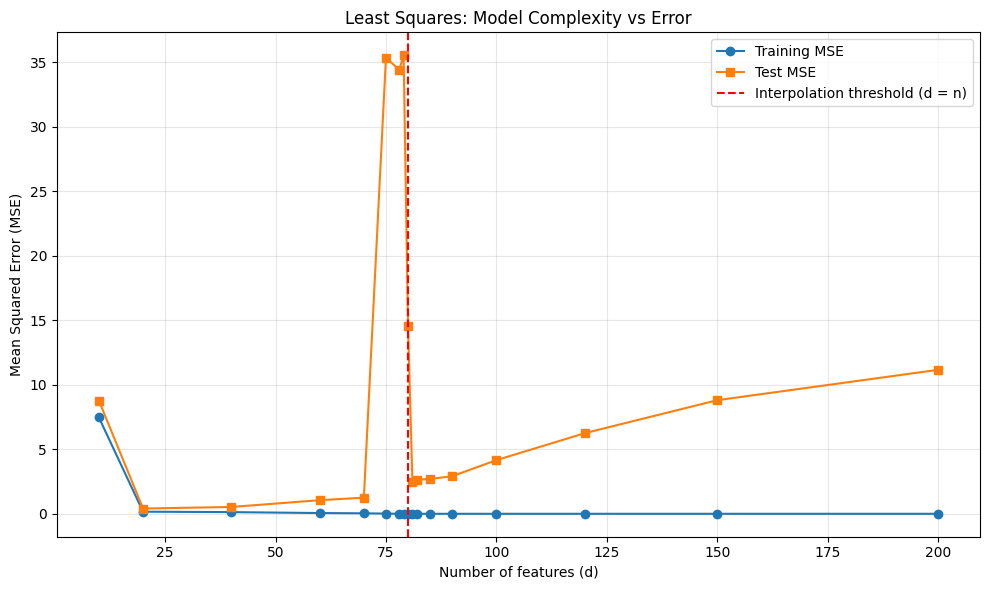

In [63]:

import matplotlib.pyplot as plt

# Plot Least Squares error as model complexity increases
plt.figure(figsize=(10, 6))

plt.plot(dimensions, ls_train_errors, marker="o",
         label="Training MSE")

plt.plot(dimensions, ls_test_errors, marker="s",
         label="Test MSE")

# Mark the interpolation threshold
plt.axvline(x=80, color="red", linestyle="--",
            label="Interpolation threshold (d = n)")

plt.xlabel("Number of features (d)")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Least Squares: Model Complexity vs Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [64]:

# Ridge Regression across feature dimensions
ridge_train_errors = []
ridge_test_errors = []

alpha = 1.0

for d in dimensions:
    X_tr = X_train_dd[:, :d]
    X_te = X_test_dd[:, :d]

    # Fit Ridge Regression
    w = ridge_regression(X_tr, y_train_dd, alpha=alpha)

    # Evaluate training and test error
    train_error = np.mean((y_train_dd - X_tr @ w) ** 2)
    test_error = np.mean((y_test_dd - X_te @ w) ** 2)

    ridge_train_errors.append(train_error)
    ridge_test_errors.append(test_error)

    print(f"d={d:3d} | Train MSE={train_error:.4f} | Test MSE={test_error:.4f}")


d= 10 | Train MSE=7.4759 | Test MSE=8.7621
d= 20 | Train MSE=0.1680 | Test MSE=0.3729
d= 40 | Train MSE=0.1350 | Test MSE=0.4970
d= 60 | Train MSE=0.0672 | Test MSE=0.9113
d= 70 | Train MSE=0.0491 | Test MSE=1.2504
d= 75 | Train MSE=0.0420 | Test MSE=1.6392
d= 78 | Train MSE=0.0251 | Test MSE=2.0327
d= 79 | Train MSE=0.0259 | Test MSE=2.0096
d= 80 | Train MSE=0.0225 | Test MSE=2.0282
d= 81 | Train MSE=0.0119 | Test MSE=2.0314
d= 82 | Train MSE=0.0117 | Test MSE=2.1168
d= 85 | Train MSE=0.0125 | Test MSE=2.1870
d= 90 | Train MSE=0.0111 | Test MSE=2.5904
d=100 | Train MSE=0.0087 | Test MSE=3.9018
d=120 | Train MSE=0.0040 | Test MSE=6.1129
d=150 | Train MSE=0.0016 | Test MSE=8.7933
d=200 | Train MSE=0.0008 | Test MSE=11.1514


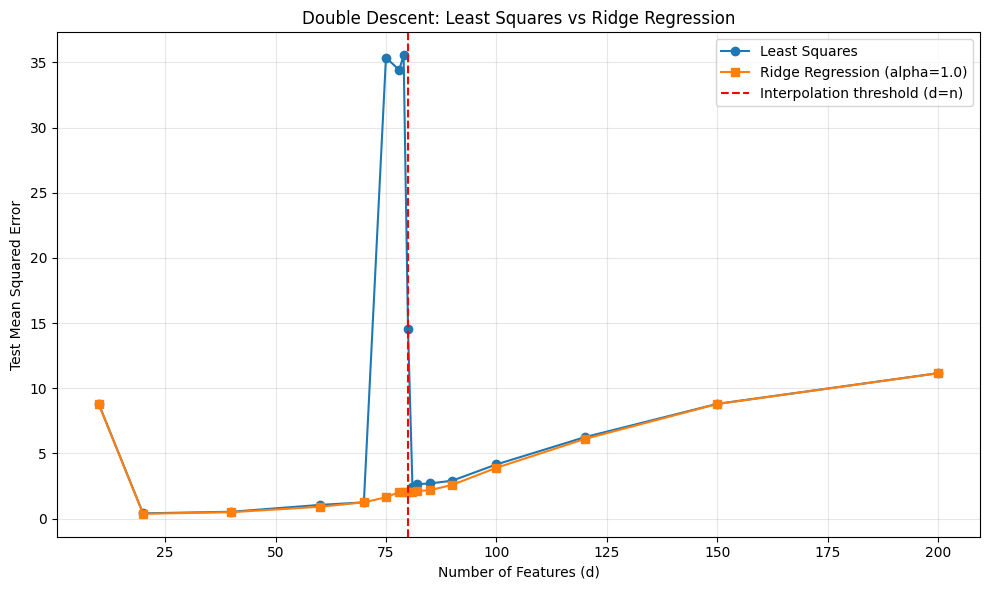

In [65]:

# Compare Least Squares and Ridge Regression
plt.figure(figsize=(10, 6))

plt.plot(dimensions, ls_test_errors, marker="o",
         label="Least Squares")

plt.plot(dimensions, ridge_test_errors, marker="s",
         label="Ridge Regression (alpha=1.0)")

plt.axvline(x=80, color="red", linestyle="--",
            label="Interpolation threshold (d=n)")

plt.xlabel("Number of Features (d)")
plt.ylabel("Test Mean Squared Error")
plt.title("Double Descent: Least Squares vs Ridge Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [66]:

# Generate synthetic data with dense signal
X_train_dense, X_test_dense, y_train_dense, y_test_dense = generate_dense_signal_data(
    n_train=80,
    n_test=500,
    max_features=500,
    noise_std=0.5,
    random_state=42
)

print("Dense Signal Dataset")
print("----------------------------")
print("Training features:", X_train_dense.shape)
print("Test features:", X_test_dense.shape)
print("Training targets:", y_train_dense.shape)
print("Test targets:", y_test_dense.shape)


Dense Signal Dataset
----------------------------
Training features: (80, 500)
Test features: (500, 500)
Training targets: (80,)
Test targets: (500,)


In [67]:

# Feature dimensions for the dense-signal experiment
dense_dimensions = [10, 20, 40, 60, 70, 75, 78, 79,
                    80, 81, 82, 85, 90, 100, 120,
                    150, 200, 300, 400, 500]

dense_train_errors = []
dense_test_errors = []

for d in dense_dimensions:
    X_tr = X_train_dense[:, :d]
    X_te = X_test_dense[:, :d]

    # Train Least Squares
    w = least_squares(X_tr, y_train_dense)

    # Calculate Mean Squared Error
    train_mse = np.mean((y_train_dense - X_tr @ w) ** 2)
    test_mse = np.mean((y_test_dense - X_te @ w) ** 2)

    dense_train_errors.append(train_mse)
    dense_test_errors.append(test_mse)

    print(f"d={d:3d} | Train MSE={train_mse:.4f} | Test MSE={test_mse:.4f}")


d= 10 | Train MSE=1.0381 | Test MSE=1.4581
d= 20 | Train MSE=0.8008 | Test MSE=2.0278
d= 40 | Train MSE=0.6021 | Test MSE=3.0144
d= 60 | Train MSE=0.4050 | Test MSE=4.8841
d= 70 | Train MSE=0.1932 | Test MSE=11.5030
d= 75 | Train MSE=0.1132 | Test MSE=18.7506
d= 78 | Train MSE=0.0167 | Test MSE=2194.9310
d= 79 | Train MSE=0.0012 | Test MSE=18231.8155
d= 80 | Train MSE=0.0000 | Test MSE=19795.5859
d= 81 | Train MSE=0.0000 | Test MSE=504.7210
d= 82 | Train MSE=0.0000 | Test MSE=121.3045
d= 85 | Train MSE=0.0000 | Test MSE=39.6470
d= 90 | Train MSE=0.0000 | Test MSE=18.1821
d=100 | Train MSE=0.0000 | Test MSE=9.8883
d=120 | Train MSE=0.0000 | Test MSE=4.0229
d=150 | Train MSE=0.0000 | Test MSE=2.8975
d=200 | Train MSE=0.0000 | Test MSE=1.9552
d=300 | Train MSE=0.0000 | Test MSE=1.4573
d=400 | Train MSE=0.0000 | Test MSE=1.2763
d=500 | Train MSE=0.0000 | Test MSE=1.1816


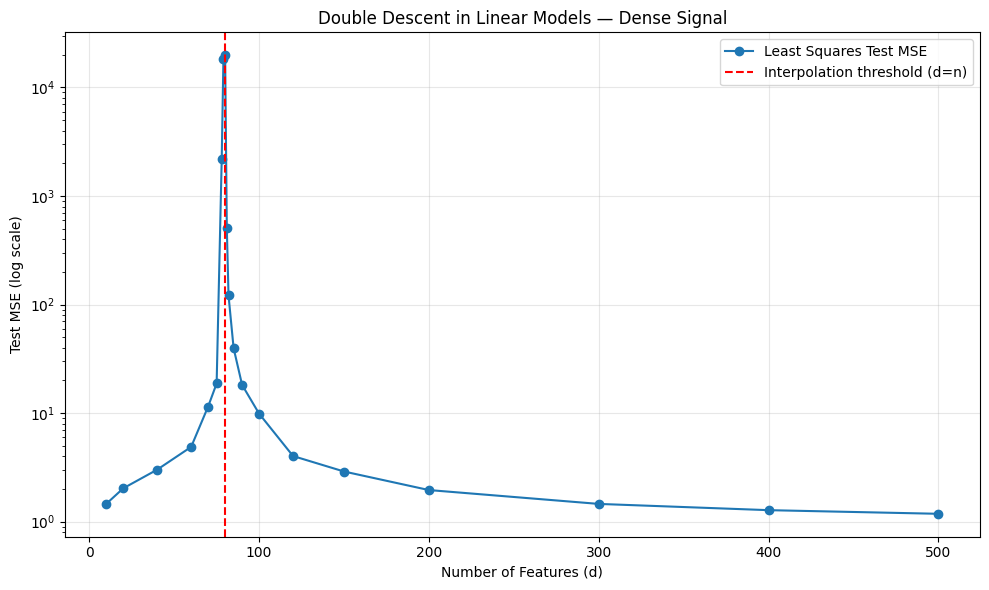

In [79]:

# Double Descent on dense-signal synthetic data
plt.figure(figsize=(10, 6))

plt.plot(
    dense_dimensions,
    dense_test_errors,
    marker="o",
    label="Least Squares Test MSE"
)

plt.axvline(
    x=80,
    color="red",
    linestyle="--",
    label="Interpolation threshold (d=n)"
)

plt.yscale("log")
plt.xlabel("Number of Features (d)")
plt.ylabel("Test MSE (log scale)")
plt.title("Double Descent in Linear Models — Dense Signal")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save graph
plt.savefig(
    results_dir / "synthetic_double_descent.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [80]:

# Ridge Regression on the dense-signal dataset
dense_ridge_train_errors = []
dense_ridge_test_errors = []

alpha = 1.0

for d in dense_dimensions:
    X_tr = X_train_dense[:, :d]
    X_te = X_test_dense[:, :d]

    # Train Ridge Regression
    w = ridge_regression(X_tr, y_train_dense, alpha=alpha)

    # Calculate training and test MSE
    train_mse = np.mean((y_train_dense - X_tr @ w) ** 2)
    test_mse = np.mean((y_test_dense - X_te @ w) ** 2)

    dense_ridge_train_errors.append(train_mse)
    dense_ridge_test_errors.append(test_mse)

    print(f"d={d:3d} | Train MSE={train_mse:.4f} | Test MSE={test_mse:.4f}")


d= 10 | Train MSE=1.0381 | Test MSE=1.4534
d= 20 | Train MSE=0.8010 | Test MSE=1.9944
d= 40 | Train MSE=0.6031 | Test MSE=2.8368
d= 60 | Train MSE=0.4106 | Test MSE=3.8869
d= 70 | Train MSE=0.2172 | Test MSE=6.1518
d= 75 | Train MSE=0.1568 | Test MSE=7.0301
d= 78 | Train MSE=0.1576 | Test MSE=6.6427
d= 79 | Train MSE=0.1504 | Test MSE=6.7356
d= 80 | Train MSE=0.1442 | Test MSE=6.9027
d= 81 | Train MSE=0.1250 | Test MSE=7.4757
d= 82 | Train MSE=0.1189 | Test MSE=7.7111
d= 85 | Train MSE=0.0773 | Test MSE=7.2595
d= 90 | Train MSE=0.0385 | Test MSE=5.9774
d=100 | Train MSE=0.0184 | Test MSE=5.2745
d=120 | Train MSE=0.0022 | Test MSE=3.6790
d=150 | Train MSE=0.0007 | Test MSE=2.7936
d=200 | Train MSE=0.0001 | Test MSE=1.9375
d=300 | Train MSE=0.0000 | Test MSE=1.4540
d=400 | Train MSE=0.0000 | Test MSE=1.2753
d=500 | Train MSE=0.0000 | Test MSE=1.1813


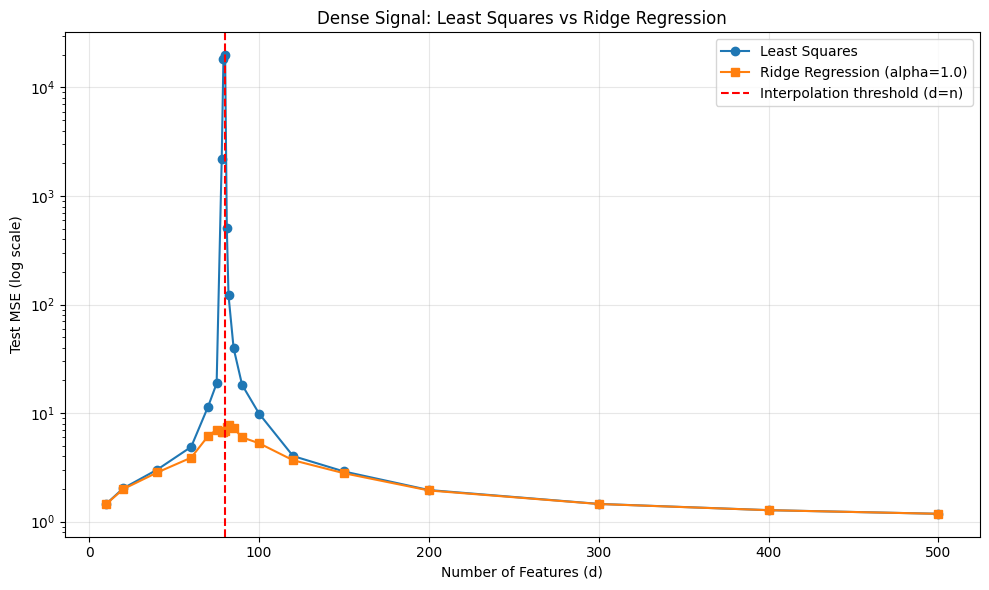

In [90]:

# Compare Least Squares and Ridge Regression
plt.figure(figsize=(10, 6))

plt.plot(
    dense_dimensions,
    dense_test_errors,
    marker="o",
    label="Least Squares"
)

plt.plot(
    dense_dimensions,
    dense_ridge_test_errors,
    marker="s",
    label="Ridge Regression (alpha=1.0)"
)

plt.axvline(
    x=80,
    color="red",
    linestyle="--",
    label="Interpolation threshold (d=n)"
)

plt.yscale("log")
plt.xlabel("Number of Features (d)")
plt.ylabel("Test MSE (log scale)")
plt.title("Dense Signal: Least Squares vs Ridge Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save graph
plt.savefig(
    results_dir / "synthetic_ridge_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [91]:

# Repeat the dense-signal experiment across random seeds
seeds = range(10)

repeated_test_errors = []

for seed in seeds:
    X_tr_full, X_te_full, y_tr, y_te = generate_dense_signal_data(
        n_train=80,
        n_test=500,
        max_features=500,
        noise_std=0.5,
        random_state=seed
    )

    seed_errors = []

    for d in dense_dimensions:
        X_tr = X_tr_full[:, :d]
        X_te = X_te_full[:, :d]

        w = least_squares(X_tr, y_tr)
        test_mse = np.mean((y_te - X_te @ w) ** 2)

        seed_errors.append(test_mse)

    repeated_test_errors.append(seed_errors)

# Calculate summary statistics across seeds
repeated_test_errors = np.array(repeated_test_errors)

mean_test_errors = np.mean(repeated_test_errors, axis=0)
median_test_errors = np.median(repeated_test_errors, axis=0)

print("Repeated experiments completed!")
print("Number of random seeds:", len(seeds))
print("Results shape:", repeated_test_errors.shape)
print()
print(f"{'Features':<12} {'Mean Test MSE':<18} {'Median Test MSE'}")

for d, mean_mse, median_mse in zip(
    dense_dimensions, mean_test_errors, median_test_errors
):
    print(f"{d:<12} {mean_mse:<18.4f} {median_mse:.4f}")


Repeated experiments completed!
Number of random seeds: 10
Results shape: (10, 20)

Features     Mean Test MSE      Median Test MSE
10           1.3956             1.4233
20           1.6641             1.7077
40           2.2991             2.2861
60           4.1578             4.0864
70           6.9518             6.4928
75           16.5171            12.1854
78           54.1851            36.8881
79           49.1249            38.8278
80           4680.8336          76.6955
81           980.8033           51.7609
82           37.3844            34.7748
85           14.1061            14.9978
90           7.9946             7.9744
100          4.5655             4.3887
120          3.0355             3.1450
150          2.0860             2.1039
200          1.5809             1.6294
300          1.2741             1.2725
400          1.1512             1.1413
500          1.1126             1.1080


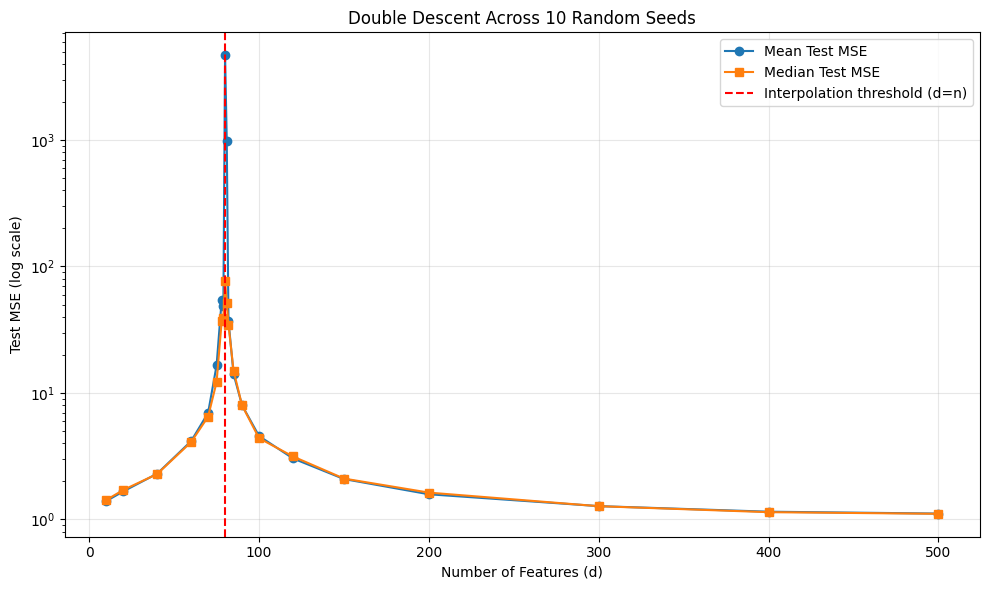

In [99]:

# Mean and median test MSE across 10 random seeds
plt.figure(figsize=(10, 6))

plt.plot(
    dense_dimensions,
    mean_test_errors,
    marker="o",
    label="Mean Test MSE"
)

plt.plot(
    dense_dimensions,
    median_test_errors,
    marker="s",
    label="Median Test MSE"
)

plt.axvline(
    x=80,
    color="red",
    linestyle="--",
    label="Interpolation threshold (d=n)"
)

plt.yscale("log")
plt.xlabel("Number of Features (d)")
plt.ylabel("Test MSE (log scale)")
plt.title("Double Descent Across 10 Random Seeds")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save graph
plt.savefig(
    results_dir / "synthetic_repeated_experiments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [100]:

# Prepare training and validation data for Ridge tuning
rng = np.random.default_rng(42)
indices = rng.permutation(len(y_train_dense))

train_idx = indices[:60]
val_idx = indices[60:]

X_fit = X_train_dense[train_idx]
y_fit = y_train_dense[train_idx]

X_val = X_train_dense[val_idx]
y_val = y_train_dense[val_idx]

print("Training samples:", len(y_fit))
print("Validation samples:", len(y_val))
print("Test samples (untouched):", len(y_test_dense))


Training samples: 60
Validation samples: 20
Test samples (untouched): 500


In [101]:

# Select Ridge regularization using validation data
alpha_values = [0.01, 0.1, 1.0, 10.0, 100.0]
validation_errors = []

d = 80

for alpha in alpha_values:
    # Fit using only the training subset
    w = ridge_regression(X_fit[:, :d], y_fit, alpha=alpha)

    # Evaluate on validation data
    predictions = X_val[:, :d] @ w
    val_mse = np.mean((y_val - predictions) ** 2)

    validation_errors.append(val_mse)

    print(f"alpha={alpha:6.2f} | Validation MSE={val_mse:.4f}")

# Select alpha with lowest validation error
best_index = np.argmin(validation_errors)
best_alpha = alpha_values[best_index]

print("--------------------------------")
print(f"Best alpha: {best_alpha}")
print(f"Lowest validation MSE: {validation_errors[best_index]:.4f}")


alpha=  0.01 | Validation MSE=7.3869
alpha=  0.10 | Validation MSE=7.1340
alpha=  1.00 | Validation MSE=5.4273
alpha= 10.00 | Validation MSE=2.3899
alpha=100.00 | Validation MSE=1.0644
--------------------------------
Best alpha: 100.0
Lowest validation MSE: 1.0644


In [102]:

# Expanded Ridge hyperparameter search
alpha_values = [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 200.0, 500.0, 1000.0]

validation_errors = []
d = 80

for alpha in alpha_values:
    w = ridge_regression(X_fit[:, :d], y_fit, alpha=alpha)

    predictions = X_val[:, :d] @ w
    val_mse = np.mean((y_val - predictions) ** 2)

    validation_errors.append(val_mse)

    print(f"alpha={alpha:7.2f} | Validation MSE={val_mse:.4f}")

best_index = np.argmin(validation_errors)
best_alpha = alpha_values[best_index]

print("--------------------------------")
print(f"Best alpha: {best_alpha}")
print(f"Lowest validation MSE: {validation_errors[best_index]:.4f}")


alpha=   0.01 | Validation MSE=7.3869
alpha=   0.10 | Validation MSE=7.1340
alpha=   1.00 | Validation MSE=5.4273
alpha=  10.00 | Validation MSE=2.3899
alpha=  50.00 | Validation MSE=1.3002
alpha= 100.00 | Validation MSE=1.0644
alpha= 200.00 | Validation MSE=0.9275
alpha= 500.00 | Validation MSE=0.8411
alpha=1000.00 | Validation MSE=0.8132
--------------------------------
Best alpha: 1000.0
Lowest validation MSE: 0.8132


In [103]:

# Investigate stronger regularization
alpha_values_extended = [100, 200, 500, 1000, 2000, 5000, 10000, 100000]

extended_errors = []
d = 80

for alpha in alpha_values_extended:
    w = ridge_regression(X_fit[:, :d], y_fit, alpha=alpha)

    predictions = X_val[:, :d] @ w
    val_mse = np.mean((y_val - predictions) ** 2)

    extended_errors.append(val_mse)

    print(f"alpha={alpha:8.0f} | Validation MSE={val_mse:.4f}")

best_index = np.argmin(extended_errors)
best_alpha = alpha_values_extended[best_index]

print("--------------------------------")
print(f"Selected alpha: {best_alpha}")
print(f"Validation MSE: {extended_errors[best_index]:.4f}")


alpha=     100 | Validation MSE=1.0644
alpha=     200 | Validation MSE=0.9275
alpha=     500 | Validation MSE=0.8411
alpha=    1000 | Validation MSE=0.8132
alpha=    2000 | Validation MSE=0.8001
alpha=    5000 | Validation MSE=0.7926
alpha=   10000 | Validation MSE=0.7902
alpha=  100000 | Validation MSE=0.7880
--------------------------------
Selected alpha: 100000
Validation MSE: 0.7880


In [104]:

# Compare strongly regularized Ridge with a zero baseline
d = 80

# Zero baseline predictions
zero_predictions = np.zeros_like(y_val)
zero_mse = np.mean((y_val - zero_predictions) ** 2)

# Ridge predictions with selected alpha
w = ridge_regression(X_fit[:, :d], y_fit, alpha=best_alpha)
ridge_predictions = X_val[:, :d] @ w

ridge_mse = np.mean((y_val - ridge_predictions) ** 2)

print("Validation Comparison")
print("----------------------------")
print(f"Zero baseline MSE: {zero_mse:.4f}")
print(f"Ridge MSE:         {ridge_mse:.4f}")
print(f"Selected alpha:    {best_alpha}")


Validation Comparison
----------------------------
Zero baseline MSE: 0.7878
Ridge MSE:         0.7880
Selected alpha:    100000


In [105]:

# Final Ridge evaluation at d = 80
d = 80

# Refit using all 80 training samples
final_weights = ridge_regression(
    X_train_dense[:, :d],
    y_train_dense,
    alpha=best_alpha
)

# Evaluate on the untouched test set
final_predictions = X_test_dense[:, :d] @ final_weights
final_test_mse = np.mean((y_test_dense - final_predictions) ** 2)

# Compare with zero baseline
zero_test_mse = np.mean(y_test_dense ** 2)

print("Final Test Evaluation")
print("--------------------------------")
print(f"Selected alpha: {best_alpha}")
print(f"Ridge Test MSE: {final_test_mse:.4f}")
print(f"Zero Baseline Test MSE: {zero_test_mse:.4f}")


Final Test Evaluation
--------------------------------
Selected alpha: 100000
Ridge Test MSE: 1.2854
Zero Baseline Test MSE: 1.2854
